In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, r"c:\users\arthu\documents\swittz-epfl\phd\code\lib\site-packages")
sys.path.append('../')
from pygraphon.graphons import StepGraphon
from pygraphon.estimators import SmoothNetHist

from experiments.utils_generators import AssociativeFullyRandom
from pygraphon.norm import MseProbaEdge, MaeProbaEdge, AUCEdge, AUPRCEdge
from pygraphon.plots.plot_matrices import spy


/home/verdeyme/pygraphon/env/lib/python3.9/site-packages/scipy/integrate/_quadpack_py.py:1233: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,


In [4]:
from palettable.colorbrewer.sequential import YlOrRd_9
# To get the colors as a list of RGB tuples:
colors = YlOrRd_9.mpl_colors
hex_colors = YlOrRd_9.hex_colors
import matplotlib.cm as cm
import matplotlib.colors as colors
cmap = cm.get_cmap('YlOrRd')


/tmp/ipykernel_8948/3643435566.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('YlOrRd')


# Common graphons

In [ ]:
from pygraphon.graphons import common_graphons
n = 40
estimators = {g: {"SSM": None, "Olhede": None} for _,g in enumerate(common_graphons.values())}
for j,g in enumerate(common_graphons.values()):
    adj_mat = g.draw(n=n, exchangeable=False)
    est = SmoothNetHist()
    est.fit(adj_mat)
    estimators[g]["SSM"] = est.graphon
    estimators[g]["Olhede"] = est._first_approximate_graphon_from_adjacency(adj_mat)


In [ ]:
from pygraphon.graphons import common_graphons
common_graphons

In [ ]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(12, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)/estimators[g]["SSM"].initial_rho, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)/estimators[g]["Olhede"][0].initial_rho, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)/g.initial_rho, cmap = cmap, origin='lower')
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

In [ ]:
#Plot each graphn and its estimate in subplots iteratively
fig, axes = plt.subplots(nrows=len(common_graphons.values()), ncols=3, figsize=(20, 20))
for j,g in enumerate(common_graphons.values()):
    axes[j,0].imshow(estimators[g]["SSM"].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,0].set_title("nLC = " + str(len(np.unique(estimators[g]["SSM"].graphon))))
    axes[j,1].imshow(estimators[g]["Olhede"][0].get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,1].set_title("nLC = " + str(len(np.unique(estimators[g]["Olhede"][0].graphon))))
    axes[j,2].imshow(g.get_edge_probabilities(n,False,True)**0.25, cmap = cmap)
    axes[j,2].set_title(str(g))
plt.tight_layout()
plt.show()

# HSBM, overlap, and partition model

## HSBM and partition

In [60]:
n=1000

### Regular HSBM

In [61]:
from utils_generators import generate_hierarchical_theta

# Example usage:
k = 15
m = 3
theta_min_intra = 0.5
theta_max_intra = 0.7
theta_min_meta_intra = 0.4
theta_max_meta_intra = 0.4
theta_min_inter = 0.1
theta_max_inter = 0.3

# put theta_inter's and theta_meta_intra's to equality to get partition model

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)
print(theta.shape)


(15, 15)


In [62]:
graphon = StepGraphon(theta, bandwidthHist=1 /k)

In [63]:
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

In [64]:
print(est.graphon)
print(estimators_Olhede[0])

StepGraphon 
[[0.577 0.406 0.406 0.430 0.430 0.147 0.167 0.147 0.230 0.187 0.167 0.253
  0.230 0.211 0.121 0.077]
 [0.406 0.541 0.406 0.406 0.406 0.253 0.121 0.121 0.121 0.167 0.167 0.147
  0.121 0.121 0.121 0.147]
 [0.406 0.406 0.490 0.406 0.406 0.282 0.253 0.253 0.167 0.121 0.230 0.121
  0.187 0.121 0.121 0.077]
 [0.430 0.406 0.406 0.657 0.406 0.211 0.147 0.187 0.211 0.230 0.253 0.187
  0.187 0.230 0.147 0.121]
 [0.430 0.406 0.406 0.406 0.490 0.282 0.282 0.211 0.230 0.187 0.187 0.187
  0.282 0.282 0.211 0.211]
 [0.147 0.253 0.282 0.211 0.282 0.490 0.167 0.230 0.253 0.253 0.406 0.282
  0.373 0.373 0.373 0.406]
 [0.167 0.121 0.253 0.147 0.282 0.167 0.577 0.406 0.406 0.406 0.121 0.406
  0.167 0.253 0.167 0.167]
 [0.147 0.121 0.253 0.187 0.211 0.230 0.406 0.490 0.406 0.373 0.230 0.406
  0.253 0.230 0.211 0.230]
 [0.230 0.121 0.167 0.211 0.230 0.253 0.406 0.406 0.430 0.430 0.187 0.430
  0.187 0.211 0.167 0.211]
 [0.187 0.167 0.121 0.230 0.187 0.253 0.406 0.373 0.430 0.541 0.187 0.430
  0.

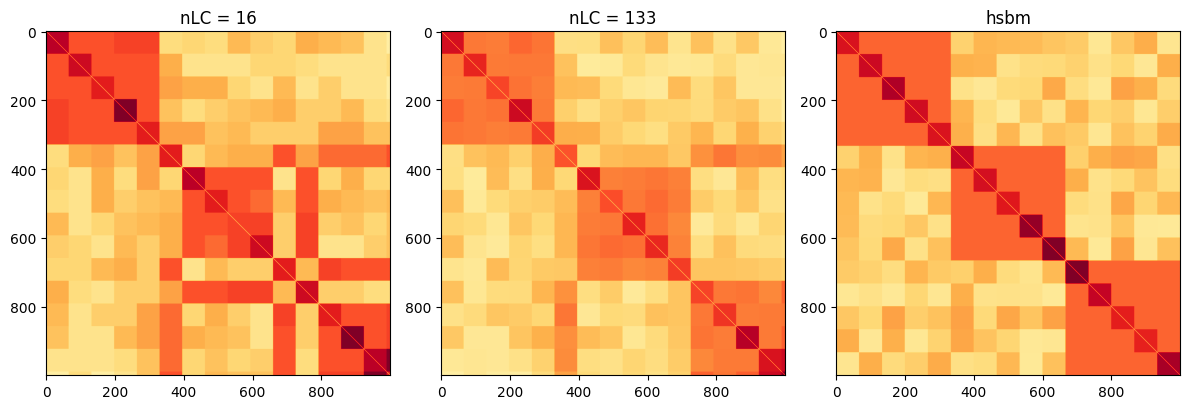

In [65]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = cmap)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = cmap)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

### Mix between HSBM and Partition

In [66]:
k = 15
m = 3
theta_min_intra = 0.5
theta_max_intra = 0.7
theta_min_meta_intra = 0.25
theta_max_meta_intra = 0.25
theta_min_inter = 0.15
theta_max_inter = 0.15

# put theta_inter's and theta_meta_intra's to equality to get partition model

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)

In [67]:
graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

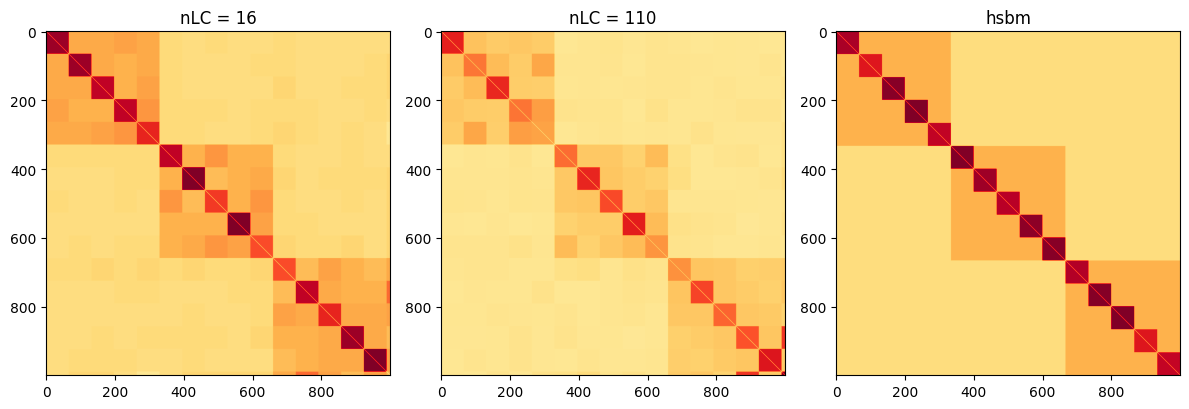

In [68]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = cmap)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = cmap)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

### Partition model

In [69]:
k = 3
m = 1
theta_min_intra = 0.7
theta_max_intra = 0.7
theta_min_meta_intra = 0.2
theta_max_meta_intra = 0.2
theta_min_inter = 0.2
theta_max_inter = 0.2

# put m=1 to get partition model, p_ext will be defined by meta-intra-connectivity

theta = generate_hierarchical_theta(k, m, theta_min_intra, theta_max_intra, theta_min_meta_intra, theta_max_meta_intra, theta_min_inter, theta_max_inter)
print(theta)

[[0.7 0.2 0.2]
 [0.2 0.7 0.2]
 [0.2 0.2 0.7]]


In [70]:
graphon = StepGraphon(theta, bandwidthHist=1 /k)
adj_mat = graphon.draw(n=n, exchangeable=False)
est = SmoothNetHist(bandwidth=1/k)
est.fit(adj_mat)
estimators_SSM = est.graphon
estimators_Olhede = est._first_approximate_graphon_from_adjacency(adj_mat, bandwidthHist=1/k)

In [71]:
print(est.graphon)
print(estimators_Olhede[0])

StepGraphon 
[[0.699 0.200 0.200 0.200]
 [0.200 0.699 0.200 0.329]
 [0.200 0.200 0.699 0.699]
 [0.200 0.329 0.699 0.500]]

 [0.110 0.110 0.110 0.001] (size of the blocks)
StepGraphon 
[[0.700 0.201 0.198 0.204]
 [0.201 0.701 0.201 0.368]
 [0.198 0.201 0.697 0.574]
 [0.204 0.368 0.574 0.833]]

 [0.110 0.110 0.110 0.001] (size of the blocks)


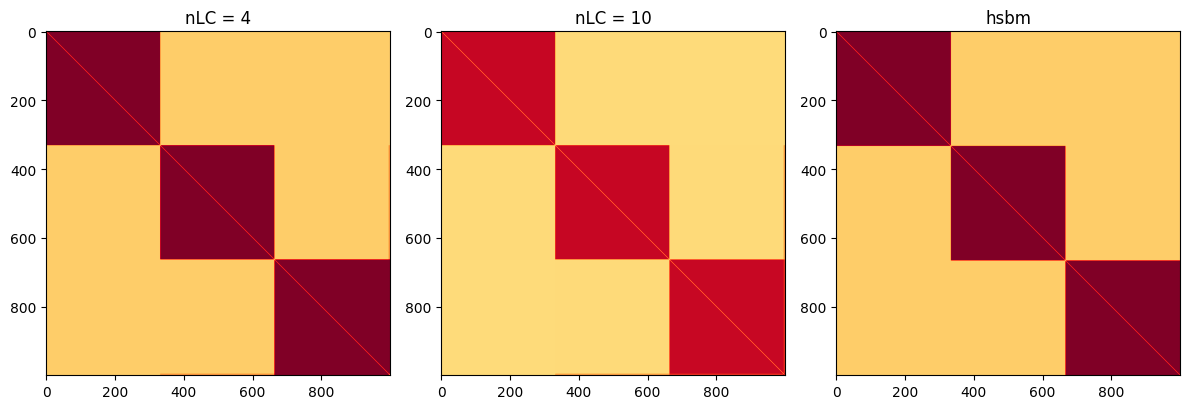

In [72]:
fig, axes = plt.subplots(ncols=3, figsize=(12, 20))
axes[0].imshow(estimators_SSM.get_edge_probabilities(n,False,True)/estimators_SSM.initial_rho, cmap = cmap)
axes[0].set_title("nLC = " + str(len(np.unique(estimators_SSM.graphon))))
axes[1].imshow(estimators_Olhede[0].get_edge_probabilities(n,False,True)/estimators_Olhede[0].initial_rho, cmap = cmap)
axes[1].set_title("nLC = " + str(len(np.unique(estimators_Olhede[0].graphon))))
axes[2].imshow(graphon.get_edge_probabilities(n,False,True)/graphon.initial_rho, cmap = cmap)
axes[2].set_title("hsbm")
plt.tight_layout()
plt.show()

## OSBM

In [73]:
import numpy as np

def generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter):
    """
    Generate a symmetric connectivity matrix θ for an OSBM with specific inter-connectivity behavior.

    Parameters:
    - k: total number of blocks (should be at least 3)
    - shared_inter_sets: number of sets of blocks with shared inter-connectivity values
    - theta_min_intra, theta_max_intra: intra-connectivity range within a block
    - theta_min_inter, theta_max_inter: inter-connectivity range between blocks

    Returns:
    - θ: k x k symmetric connectivity matrix for OSBM
    """
    
    if k < 3:
        raise ValueError("The number of blocks k should be at least 3.")

    theta = np.zeros((k, k))
    shared_sets = [np.random.choice(k, 3, replace=False) for _ in range(shared_inter_sets)]

    for i in range(k):
        for j in range(i, k):  # Only loop over the upper triangle including the diagonal
            
            shared_value = None
            for shared_set in shared_sets:
                if i in shared_set and j in shared_set and i != j:
                    if shared_value is None:
                        shared_value = np.random.uniform(theta_min_inter, theta_max_inter)
                    theta[i, j] = shared_value
                    break

            if i == j:
                theta[i, j] = np.random.uniform(theta_min_intra, theta_max_intra)
            elif theta[i, j] == 0:
                theta[i, j] = np.random.uniform(theta_min_inter, theta_max_inter)
            
            # Make the matrix symmetric
            theta[j, i] = theta[i, j]

    return theta

# Example usage:
k = 5
shared_inter_sets = 2
theta_min_intra = 0.7
theta_max_intra = 1.0
theta_min_inter = 0.1
theta_max_inter = 0.3

theta = generate_osbm_theta(k, shared_inter_sets, theta_min_intra, theta_max_intra, theta_min_inter, theta_max_inter)
print(theta)


[[0.95896875 0.1942077  0.1717554  0.12575534 0.22677635]
 [0.1942077  0.94151084 0.14167822 0.2761682  0.24666684]
 [0.1717554  0.14167822 0.79706096 0.19035255 0.16222398]
 [0.12575534 0.2761682  0.19035255 0.81195768 0.18674392]
 [0.22677635 0.24666684 0.16222398 0.18674392 0.76414169]]


# SSM